# Construindo uma Rede Neural

### Cenário
Uma empresa de e-commerce deseja estimar a **probabilidade de atraso de uma entrega**.

Cada pedido será representado por três características já normalizadas:

- `distancia`
- `quantidade_itens`
- `frete`

O alvo é:

\
y =
\begin{cases}
0 & \text{entrega no prazo}\\
1 & \text{entrega atrasada}
\end{cases}


### Objetivo

Ao longo desta atividade, você irá construir uma pequena rede neural para classificação binária só utilizando tensorflow.

Ao final, deverá compreender o fluxo:

> **Regra da aula:** não utilize `model.fit()`. Hoje queremos entender como a rede **produz uma predição**. O treinamento será estudado na próxima aula.

## Preparação

Execute a célula abaixo para importar as bibliotecas necessárias.

In [2]:
import sys

print(sys.executable)

c:\Users\bianc\python.exe


In [1]:
import tensorflow as tf
import numpy as np

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# Tarefa 1: Representando os dados

Considere os seguintes pedidos:

| Pedido | Distância | Quantidade de itens | Frete | Atrasou? |
|---|---:|---:|---:|---:|
| 1 | 0.20 | 0.10 | 0.30 | 0 |
| 2 | 0.80 | 0.70 | 0.90 | 1 |
| 3 | 0.30 | 0.20 | 0.40 | 0 |
| 4 | 0.90 | 0.80 | 0.70 | 1 |
| 5 | 0.15 | 0.30 | 0.20 | 0 |
| 6 | 0.75 | 0.60 | 0.85 | 1 |

### Sua tarefa

Crie:

- um tensor `X` contendo as três features;
- um tensor `y` contendo o alvo.

Utilize `dtype=tf.float32`.

Depois, exiba os shapes de `X` e `y`.

### Antes de programar

Responda:

**Qual deve ser o shape de `X`?**

Resposta: `X.shape(6, 3)`

**Qual deve ser o shape de `y`?**

Resposta: `Y.shape(6,)`


6 pedidos com 3 características (distância, quantidade_itens e frete)

y possui uma resposta para cada um dos 6 pedidos (vetor com 6 valore)

In [2]:
X = tf.constant([
    [0.20, 0.10, 0.30],
    [0.80, 0.70, 0.90],
    [0.30, 0.20, 0.40],
    [0.90, 0.80, 0.70],
    [0.15, 0.30, 0.20],
    [0.75, 0.60, 0.85]
], dtype=tf.float32)

y = tf.constant([
    0,
    1,
    0,
    1,
    0,
    1
], dtype=tf.float32)

print(X.shape)
print(y.shape)

(6, 3)
(6,)


### Verificação conceitual

Complete:

Cada **linha** de `X` representa `um pedido`.

Cada **coluna** de `X` representa `uma característica (feature)`.

O valor `y = 1` significa `que o pedido atrasou`.


# Tarefa 2: O que acontece dentro de um neurônio?

Antes de construir a rede, vamos lembrar a operação fundamental de um neurônio:

$$
\boxed{z = \sum_i x_i w_i + b}
$$

Considere o primeiro pedido:

$$
x = [0.20,\ 0.10,\ 0.30]
$$

e os seguintes parâmetros:

$$
w = [0.5,\ -0.3,\ 0.8]
$$

$$
b = 0.1
$$

### Primeiro calcule manualmente

Complete a expressão:

$$
z = (\square \times \square)
  + (\square \times \square)
  + (\square \times \square)
  + \square
$$

`z = (0.20 x 0.5) + (0.10 x -0.3) + (0.30 x 0.8) + 0.1`

Resultado esperado por você:

$$
\boxed{z = \square}
$$

`z = 0.41`

### Depois confirme utilizando TensorFlow.

In [3]:
# Pesos e bias já definidos para o exercício
w = tf.constant([0.5, -0.3, 0.8], dtype=tf.float32)
b = tf.constant(0.1, dtype=tf.float32)

# Selecione o primeiro pedido
x = X[0]

# Calcule z = soma(x * w) + b
z = tf.reduce_sum(x * w) + b

print("z =", z.numpy())

z = 0.41


### Pergunta

O valor de \(z\) representa diretamente a probabilidade de atraso?

**( ) Sim**

**(X) Não**

Justifique:
`Pois o valor de z representa apenas a combinação linear das entradas, pesos e bias. Ainda falta o passo da aplicação da função de ativação para obter a saída do neurônio.`


# Tarefa 3: Função de ativação

Até agora, o neurônio calculou uma combinação das entradas:

$$
z = \sum_i x_iw_i + b
$$

Agora precisamos aplicar uma **função de ativação**.

Nesta tarefa, utilizaremos a **ReLU (Rectified Linear Unit)**:

$$
\boxed{\operatorname{ReLU}(z)=\max(0,z)}
$$

Isso significa que a ReLU compara o valor de $z$ com zero e retorna o **maior deles**:

- se $z < 0$, a saída será **0**;
- se $z > 0$, a saída será o **próprio $z$**.

### Antes de executar o código

Complete mentalmente a tabela:

| $z$ | $\operatorname{ReLU}(z)$ |
|---:|---:|
| -3 | $\square$ |
| -0.5 | $\square$ |
| 0 | $\square$ |
| 2 | $\square$ |
| 5 | $\square$ |

Resposta:
| $z$ | $\operatorname{ReLU}(z)$ |
|---:|---:|
| -3 | 0 |
| -0.5 | 0 |
| 0 | 0 |
| 2 | 2 |
| 5 | 5 |


### Agora confirme utilizando TensorFlow

Aplique a função ReLU aos mesmos valores e compare o resultado com suas respostas.

In [4]:
valores = tf.constant([-3.0, -0.5, 0.0, 2.0, 5.0])

# Aplique ReLU
resultado = tf.nn.relu(valores)

print(resultado.numpy())

[0. 0. 0. 2. 5.]


### Pense antes de continuar

Por que uma rede neural precisa de funções de ativação **não lineares**?

`Uma rede neural precisa de funções de ativação não lineares para conseguir aprender relações complexas nos dados. Pois, sem elas, várias camadas lineares poderiam ser reduzidas a uma única transformação linear, limitando a capacidade de aprendizado da rede.`


# Tarefa 4: Projetando a arquitetura

Agora vamos construir uma **MLP (Multilayer Perceptron)** para o nosso problema de classificação.

Cada pedido possui **3 características de entrada**:

- distância;
- quantidade de itens;
- valor do frete.

Nossa rede terá a seguinte arquitetura:

$$
\boxed{3 \rightarrow 4 \rightarrow 1}
$$

Podemos interpretá-la como:

$$
\text{3 entradas}
\rightarrow
\text{4 neurônios}
\rightarrow
\text{1 saída}
$$

A configuração será:

| Camada | Quantidade | Função de ativação |
|---|---:|---|
| Entrada | 3 valores | — |
| Camada escondida | 4 neurônios | ReLU |
| Saída | 1 neurônio | Sigmoid |


### Pense no fluxo

Complete:

$$
X
\rightarrow
\boxed{\text{Dense}(4)}
\rightarrow
\boxed{\ ?\ }
\rightarrow
\boxed{\text{Dense}(1)}
\rightarrow
\boxed{\ ?\ }
\rightarrow
\hat{y}
$$

Agora vamos transformar essa arquitetura em código utilizando TensorFlow.

### Agora construa a rede

Use:

- `tf.keras.Sequential`
- `tf.keras.layers.Input`
- `tf.keras.layers.Dense`

> **Dica:** a primeira camada `Dense` deve ter 4 neurônios e a segunda deve ter 1.


Entrada:
----------------
distância
quantidade itens
frete


Rede Neural:
----------------
combina essas informações
aprende padrões


Saída:
----------------
probabilidade de atraso

In [6]:
model = tf.keras.Sequential([
    
    # entrada
    # Cada exemplo que entra na rede possui 3 valores
    # 3 características
    tf.keras.layers.Input(shape=(3,)),
    
    # camada escondida
    # 4 neurônios
    # cada neurônio recebe as 3 entradas
    tf.keras.layers.Dense(units=4, activation='relu'),
    
    # camada de saída
    # uma saída porque é classificação binária
    tf.keras.layers.Dense(units=1, activation='sigmoid')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 4)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21 (84.00 B)

 Trainable params: 21 (84.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [8]:
history = model.fit(
    X,
    y,
    epochs=50
)

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 0.6614
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.5000 - loss: 0.6607
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.5000 - loss: 0.6601
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.5000 - loss: 0.6594
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5000 - loss: 0.6588
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.5000 - loss: 0.6581
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.5000 - loss: 0.6575
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.5000 - loss: 0.6568
Epoch 9/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.5000 - loss: 0.6562
Epoch 10/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.5000 - loss: 0.6555
Epoch 11/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.5000 - loss: 0.6549
Epoch 12/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.5000 - loss: 0.6542
E

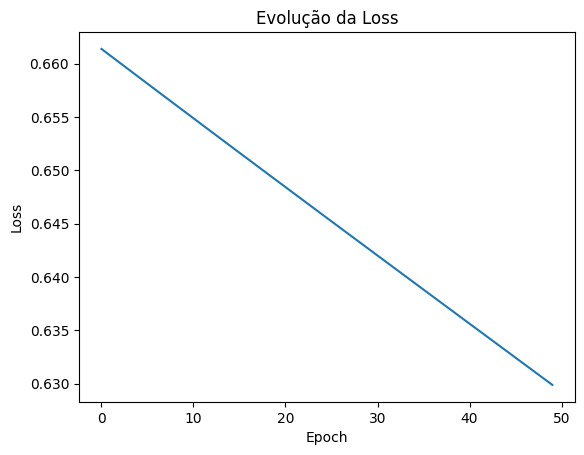

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Evolução da Loss")

plt.show()

In [10]:
predicoes = model.predict(X)

print(predicoes)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
[[0.51907486]
 [0.59167874]
 [0.531317  ]
 [0.5783535 ]
 [0.49396473]
 [0.58734393]]


# Tarefa 5: Quantos parâmetros existem?

Nossa rede possui a seguinte arquitetura:

$$
\boxed{3 \rightarrow 4 \rightarrow 1}
$$

Antes de executar `model.summary()`, vamos descobrir **manualmente** quantos parâmetros a rede precisa aprender.

Em uma camada `Dense`, cada neurônio possui:

- um **peso para cada entrada**;
- um **bias próprio**.

Assim, podemos calcular:

$$
\text{Pesos} = n_{in} \times n_{out}
$$

$$
\text{Biases} = n_{out}
$$

Portanto:

$$
\boxed{
\text{Parâmetros} =
(n_{in} \times n_{out}) + n_{out}
}
$$

---

## 1. Camada escondida

A camada escondida recebe **3 valores** e possui **4 neurônios**.

Complete:

$$
n_{in} = \square
$$
n_{in} = 3
$$
n_{out} = \square
$$
n_{out} = 4
### Quantos pesos existem?

$$
\square \times \square = \square
$$
3 x 4 = 12

### Quantos biases existem?

$$
\square
$$
1 bias para cada neurônio = 4 biases

### Total de parâmetros da camada escondida

$$
\square + \square = \boxed{\square}
$$
12 + 4 = 16

---

## 2. Camada de saída

A camada de saída recebe os valores produzidos pelos **4 neurônios da camada anterior** e possui **1 neurônio**.

Complete:

$$
n_{in} = \square
$$
n_{in} = 4
$$
n_{out} = \square
$$
n_{out} = 1
### Quantos pesos existem?

$$
\square \times \square = \square
$$
4 x 1 = 4

### Quantos biases existem?

$$
\square
$$
biases = 1

### Total de parâmetros da camada de saída

$$
\square + \square = \boxed{\square}
$$
4 + 1 = 5

---

## 3. Total da rede

Some os parâmetros das duas camadas:

$$
\boxed{
\text{Total de parâmetros} =
\square + \square =
\square
}
$$

Camada escondida:
12 pesos + 4 biases = 16

Camada de saída:
4 pesos + 1 bias = 5

Total:
16 + 5 = 21

Agora execute `model.summary()` e verifique se o resultado encontrado pela rede é igual ao seu cálculo.

In [11]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 4)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65 (264.00 B)

 Trainable params: 21 (84.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 44 (180.00 B)

`Camada escondida: 16`

`Camada de saída: 5`

`Total treinável: 21`

`Aparece 65 pois o TensorFlow/Keras está contando também os parâmetros internos do otimizador Adam. O Adam adicionou 44 parâmetros/variáveis internas para controlar a atualização dos pesos.`

### Conferência

Seu cálculo coincidiu com o TensorFlow?

**(X) Sim**

**( ) Não**

Se não, identifique onde ocorreu a diferença:

____________________________________________________________________


# Tarefa 6: Forward Pass

A arquitetura da nossa rede está pronta. Agora vamos **passar os dados pela rede** e observar o que ela produz.

Esse processo é chamado de **forward pass** (propagação para frente).

Durante o forward pass, os dados percorrem a rede da entrada até a saída:

$$
X
\rightarrow
\boxed{\text{Dense}(4)}
\rightarrow
\boxed{\text{ReLU}}
\rightarrow
\boxed{\text{Dense}(1)}
\rightarrow
\boxed{\text{Sigmoid}}
\rightarrow
\hat{y}
$$

Em outras palavras:

1. a rede recebe as características de cada pedido;
2. a camada escondida calcula combinações usando **pesos e biases**;
3. a **ReLU** é aplicada;
4. a camada de saída realiza uma nova combinação;
5. a **sigmoid** transforma o resultado em um valor entre 0 e 1.

O resultado final será:

$$
\hat{y}
$$

onde $\hat{y}$ representa a **probabilidade estimada pelo modelo** de o pedido pertencer à classe positiva (`Atrasou = 1`).

---

## Sua tarefa

Passe o tensor `X` pelo modelo e armazene o resultado em:

```python
y_pred

In [ ]:
# Forward pass

# TensorFlow pega cada exemplo de X e faz todo esse caminho automaticamente
y_pred = model(X)

# transforma o tensor do TensorFlow em um array NumPy para conseguir visualizar os valores
print(y_pred.numpy())

[[0.51907486]
 [0.59167874]
 [0.53131694]
 [0.57835346]
 [0.49396473]
 [0.58734393]]


0.519 → aproximadamente 51,9% de probabilidade de atraso.

0.592 → aproximadamente 59,2%.

0.531 → aproximadamente 53,1%.

0.578 → aproximadamente 57,8%.

0.494 → aproximadamente 49,4%.

0.587 → aproximadamente 58,7%.

In [13]:
y_pred_class = (y_pred >= 0.5).numpy().astype(int)

print(y_pred_class)

[[1]
 [1]
 [1]
 [1]
 [0]
 [1]]


`probabilidade não é a mesma coisa que classificação. Para transformar em 0 ou 1, é necessário utilizar o threshold`

`valores ≥ 0.5 seriam classificados como 1 (atrasado) e valores < 0.5 como 0 (não atrasado)`

# Tarefa 7: Probabilidade não é classe

Após o **forward pass**, o neurônio de saída utiliza a função **sigmoid**.

Por isso, a saída da rede é um valor entre 0 e 1:

$$
0 \leq \hat{y} \leq 1
$$

Esse valor pode ser interpretado como a **probabilidade estimada de o pedido pertencer à classe positiva**:

$$
\hat{y} = P(y=1 \mid X)
$$

Suponha que, para um determinado pedido, a rede produza:

$$
\boxed{\hat{y}=0.78}
$$

---

## A. O que significa $\hat{y}=0.78$?

> Resposta: Significa que a rede estima uma probabilidade de 78% de o pedido pertencer à classe positiva, ou seja, de o pedido ter atrasado (Atrasou = 1).

---

## B. Transformando probabilidade em classe

Para obter uma classe, precisamos definir um **threshold (limiar de decisão)**.

Considere inicialmente:

$$
\text{threshold}=0.5
$$

Utilizaremos a seguinte regra:

$$
\hat{y} \geq 0.5
\Rightarrow
\text{classe }1
$$

$$
\hat{y} < 0.5
\Rightarrow
\text{classe }0
$$

Para $\hat{y}=0.78$, qual classe será prevista?

$$
\boxed{\text{classe}=\square}
$$

> Resposta: classe = 1. 

---

## C. E se alterarmos o threshold?

Agora considere:

$$
\text{threshold}=0.85
$$

A probabilidade produzida pela rede continua sendo:

$$
\hat{y}=0.78
$$

Qual classe será prevista agora?

$$
\boxed{\text{classe}=\square}
$$

$$
\hat{y} \geq 0.85
\Rightarrow
\text{classe }1
$$

$$
\hat{y} < 0.85
\Rightarrow
\text{classe }0
$$

> Resposta: classe = 0.

---

## D. A rede mudou?

Ao alterar o threshold de $0.5$ para $0.85$, os pesos ou biases da rede foram modificados?

- [ ] Sim
- [X] Não

Explique:

> Resposta: Ao alterar o threshold de 0,5 para 0,85, os pesos e os biases da rede não foram modificados. O threshold apenas altera o critério utilizado para transformar a probabilidade produzida pela rede em uma classe. A rede continua produzindo a mesma probabilidade, muda só a regra de decisão.

---

## Complete o fluxo

$$
X
\rightarrow
\text{Rede Neural}
\rightarrow
\boxed{\hat{y}=0.78}
\rightarrow
\text{Threshold}
\rightarrow
\boxed{\text{Classe}}
$$

**Pergunta final:** em qual etapa a rede neural termina e em qual etapa começa a regra de decisão?

> Resposta: A rede neural termina na geração da probabilidade. A regra de decisão começa na aplicação do threshold para transformar essa probabilidade em uma classe.

## Aplicando um threshold

Agora transforme as probabilidades da sua rede em classes usando threshold `0.5`.

In [14]:
threshold = 0.5

y_class = (y_pred >= threshold).numpy().astype(int)

print("Probabilidades:")
print(y_pred.numpy())

print("\nClasses:")
print(y_class)

Probabilidades:
[[0.51907486]
 [0.59167874]
 [0.53131694]
 [0.57835346]
 [0.49396473]
 [0.58734393]]

Classes:
[[1]
 [1]
 [1]
 [1]
 [0]
 [1]]


# Tarefa 8: Comparando previsão e realidade

Agora exiba, para cada pedido:

- valor real;
- probabilidade prevista;
- classe prevista.

Complete o código.


In [16]:
for i in range(len(y)):
    real = y[i]
    probabilidade = float(y_pred[i].numpy()[0])
    classe = y_class[i]

    print(
        f"Pedido {i+1}: "
        f"real={real} | "
        f"probabilidade={probabilidade:.3f} | "
        f"classe={classe}"
    )

Pedido 1: real=0.0 | probabilidade=0.519 | classe=[1]
Pedido 2: real=1.0 | probabilidade=0.592 | classe=[1]
Pedido 3: real=0.0 | probabilidade=0.531 | classe=[1]
Pedido 4: real=1.0 | probabilidade=0.578 | classe=[1]
Pedido 5: real=0.0 | probabilidade=0.494 | classe=[0]
Pedido 6: real=1.0 | probabilidade=0.587 | classe=[1]


# Tarefa 9: Como medir o erro?

Até agora, nossa rede produziu probabilidades.

Mas surge uma pergunta importante:

> **Como podemos medir o quanto uma previsão está errada?**

Considere um pedido cujo valor verdadeiro é:

$$
\boxed{y=1}
$$

Ou seja, esse pedido **realmente atrasou**.

Agora imagine que três modelos produziram as seguintes probabilidades:

| Modelo | Probabilidade prevista |
|---|---:|
| A | $\hat{y}_A = 0.95$ |
| B | $\hat{y}_B = 0.60$ |
| C | $\hat{y}_C = 0.05$ |


> Como o valor real é 1, uma previsão próxima de 1 é boa, enquanto uma previsão próxima de 0 está muito errada.

---

## Antes de calcular qualquer coisa

### A. Qual modelo produziu a melhor previsão?

> Resposta: Modelo A, porque 0,95 é o valor mais próximo do valor real 1.

### B. Qual modelo produziu a pior previsão?

> Resposta: Modelo C, porque 0,05 está muito distante do valor real 1.

### C. Qual modelo deveria receber a maior penalização?

> Resposta: Modelo C, porque sua previsão foi a que mais se afastou da realidade.

### D. Explique seu raciocínio

> Resposta: O modelo A produziu a melhor previsão porque o valor real era y = 1 e sua previsão foi 0,95, ficando mais próxima do valor real. Já o modelo C produziu 0,05, ficando muito distante de 1 e, por isso, deve receber a maior penalização. O modelo B, com 0,60, ficou entre os dois.

---

## Pense sobre o problema

O valor verdadeiro é:

$$
y=1
$$

Portanto, quanto mais a previsão $\hat{y}$ estiver próxima de **1**, melhor deverá ser a previsão.

Mas queremos transformar essa ideia em um **número que represente o erro do modelo**.

Esse número é chamado de:

$$
\boxed{\text{Loss}}
$$

Uma boa função de Loss deve produzir:

$$
\text{boa previsão}
\Rightarrow
\text{Loss pequena}
$$

$$
\text{previsão ruim}
\Rightarrow
\text{Loss grande}
$$

Na classificação binária, uma das funções mais utilizadas para isso é a **Binary Cross-Entropy (BCE)**.

Na próxima etapa, vamos calcular a Loss de cada uma dessas previsões.

## Binary Cross-Entropy

Para problemas de **classificação binária**, uma função de Loss muito utilizada é a **Binary Cross-Entropy (BCE)**.

A ideia é simples:

> **Quanto maior a probabilidade atribuída à resposta correta, menor será a Loss.**

A fórmula é:

$$
\boxed{
L = -\left[
y\log(\hat{y}) +
(1-y)\log(1-\hat{y})
\right]
}
$$

onde:

- $y$ é o **valor verdadeiro** (`0` ou `1`);
- $\hat{y}$ é a **probabilidade prevista pelo modelo**;
- $L$ é a **Loss** da previsão.

---

### No nosso exemplo

Sabemos que:

$$
y=1
$$

Substituindo $y=1$ na fórmula:

$$
L = -\left[
1\log(\hat{y}) +
(1-1)\log(1-\hat{y})
\right]
$$

Como $(1-1)=0$:

$$
\boxed{L=-\log(\hat{y})}
$$

Portanto:

- $\hat{y}$ próximo de **1** → Loss pequena;
- $\hat{y}$ próximo de **0** → Loss grande.

Agora vamos verificar essa intuição utilizando `BinaryCrossentropy` do TensorFlow.

In [17]:
loss_fn = tf.keras.losses.BinaryCrossentropy()

y_true = tf.constant([[1.0]])

predicoes = [
    tf.constant([[0.95]]),
    tf.constant([[0.60]]),
    tf.constant([[0.05]])
]

# Calcule a loss para cada previsão

for predicao in predicoes:
    loss = loss_fn(y_true, predicao)
    print(
        "Predição:",
        float(predicao.numpy()[0, 0]),
        "| Loss:",
        float(loss.numpy())
    )

Predição: 0.949999988079071 | Loss: 0.051293306052684784
Predição: 0.6000000238418579 | Loss: 0.5108255743980408
Predição: 0.05000000074505806 | Loss: 2.995732307434082


### Interpretação

Complete:

Quanto **melhor** a previsão, geralmente `MENOR` será a loss.

Quanto mais **errada e confiante** a previsão, geralmente `MAIOR` será a loss.


# Tarefa 10: Loss da nossa rede

Agora utilize:

- os valores verdadeiros `y`;
- as probabilidades `y_pred`;

para calcular a Binary Cross-Entropy da nossa rede.

> **Importante:** utilize `y_pred`, e não as classes obtidas após o threshold.


In [18]:
# Calcule a loss da rede

loss_fn = tf.keras.losses.BinaryCrossentropy()

loss = loss_fn(y, y_pred)

print("Loss:", float(loss.numpy()))

Loss: 0.6292545199394226


# Desafio final: Como a rede aprende?

Até agora, nossa rede já consegue:

1. receber os dados de entrada;
2. realizar transformações;
3. produzir probabilidades;
4. comparar as previsões com os valores reais;
5. calcular a **Loss**.

Podemos representar o processo atual como:

$$
X
\rightarrow
\text{Rede Neural}
\rightarrow
\hat{y}
\rightarrow
\text{Loss}
$$

Mas existe um problema:

> **Os pesos e biases da nossa rede ainda não foram aprendidos.**

Eles foram apenas **inicializados**.

Para que a rede aprenda, precisamos encontrar uma maneira de ajustar seus parâmetros para produzir previsões melhores.

Isso nos leva à pergunta principal:

$$
\boxed{\text{Como podemos diminuir a Loss?}}
$$

---

## Pense antes da próxima aula

### 1. Como a rede poderia descobrir se um peso deve aumentar ou diminuir?

> Resposta: Ela compara a previsão com o valor real e calcula a Loss. A partir da Loss, é utilizado o gradiente, que indica a direção em que o parâmetro deve ser ajustado para diminuir o erro.

### 2. Como descobrir quanto esse peso deve mudar?

> Resposta: O tamanho da mudança é determinado pela combinação do gradiente com a taxa de aprendizado (learning rate).

### 3. Como saber se as mudanças realizadas estão realmente melhorando o modelo?

> Resposta: Observando a Loss durante o treinamento. Se as alterações nos pesos estiverem melhorando o modelo, a Loss tende a diminuir, indicando que as previsões estão ficando mais próximas dos valores reais.

Não é necessário saber as respostas ainda.

Na próxima aula, vamos descobrir como uma rede neural **aprende com seus próprios erros**.

$$
\boxed{
\text{Loss}
\rightarrow
\text{Gradientes}
\rightarrow
\text{Backpropagation}
\rightarrow
\text{Gradient Descent}
\rightarrow
\text{Atualização dos parâmetros}
}
$$

E estudaremos conceitos como **learning rate**, **épocas**, **batches** e o otimizador **Adam**.

---

# Checklist de aprendizagem

Antes de encerrar, marque o que você consegue explicar sem consultar o notebook:

- [ ] O que é um neurônio artificial.
- [ ] O papel de pesos e bias.
- [ ] O que representa \(z=Wx+b\).
- [ ] Por que utilizamos funções de ativação.
- [ ] Quando utilizar ReLU.
- [ ] Por que utilizamos sigmoid na saída deste problema.
- [ ] O que significa `Dense(4)`.
- [ ] Como calcular o número de parâmetros de uma camada Dense.
- [ ] O que é forward pass.
- [ ] Diferença entre probabilidade e classe.
- [ ] O papel do threshold.
- [ ] O que é uma função de loss.
- [ ] Por que a rede ainda não está aprendendo neste notebook.

## Próxima aula

**Como uma rede neural aprende?**
